<a href="https://colab.research.google.com/github/Zheleikina/ML_Zheleikina/blob/main/%D0%9B%D0%A011_%D0%96%D0%B5%D0%BB%D0%B5%D0%B9%D0%BA%D1%96%D0%BD%D0%B0_3_9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторна робота: Згорткова нейронна мережа для класифікації Fashion-MNIST

**ПІБ студента:** Желейкіна Аліна  
**Група:** 3-9  
**Дата:** 20.11.2026


### Мета роботи
Навчитися завантажувати та готувати зображення для класифікації, будувати згорткову нейронну мережу (CNN) засобами **TensorFlow / Keras**, навчати її та аналізувати результати.

### Завдання
На основі послідовності кроків у цьому шаблоні самостійно реалізуйте класифікацію зображень одягу з набору **Fashion-MNIST** (10 класів, зображення 28 × 28 пікселів). Усі комірки для коду залишено порожніми.

**Вимоги до здачі:** заповнений та виконаний `.ipynb` із виводами, графіками, прикладами прогнозів і власними висновками.

## 1. Імпорт бібліотек
Імпортуйте TensorFlow, NumPy, Matplotlib, а також потрібні модулі Keras: `Sequential`, `Input`, `Conv2D`, `MaxPooling2D`, `Dropout`, `Flatten`, `Dense`, `BatchNormalization`, `EarlyStopping`, `ReduceLROnPlateau`, `fashion_mnist`, `to_categorical`.

У вихідному прикладі також імпортовано `ImageDataGenerator`; у цій роботі він не використовується, тому його застосування необов’язкове.

In [ ]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Conv2D, MaxPooling2D, Dropout, Flatten, Dense, BatchNormalization
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.datasets import fashion_mnist
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.preprocessing.image import ImageDataGenerator
import matplotlib.pyplot as plt
import numpy as np

## 2. Завантаження даних
Завантажте **Fashion-MNIST** за допомогою `fashion_mnist.load_data()`. Збережіть навчальну та тестову вибірки у змінні `x_train`, `y_train`, `x_test`, `y_test`.

Виведіть розміри масивів, кількість класів і тип значень пікселів.

In [ ]:
(x_train, y_train), (x_test, y_test) = fashion_mnist.load_data()

print("Розмір навчальної вибірки:", x_train.shape)
print("Розмір міток навчальної вибірки:", y_train.shape)
print("Розмір тестової вибірки:", x_test.shape)
print("Розмір міток тестової вибірки:", y_test.shape)

num_classes = len(np.unique(y_train))
print("\nКількість класів:", num_classes)

print("Тип значень пікселів:", x_train.dtype)
print("Діапазон значень пікселів:", x_train.min(), "-", x_train.max())

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
Розмір навчальної вибірки: (60000, 28, 28)
Розмір міток навчальної вибірки: (60000,)
Розмір тестової вибірки: (10000, 28, 28)
Розмір міток тестової вибірки: (10000,)

Кількість класів: 10
Тип значень пікселів: uint8
Діапазон значень пікселів: 0 - 255


## 3. Підготовка зображень
Додайте до зображень вимір каналу: початкова форма окремого зображення `(28, 28)` повинна стати `(28, 28, 1)`. Використайте `np.expand_dims()` або еквівалентну операцію.

Перевірте результат за допомогою `.shape`.

In [ ]:
x_train = np.expand_dims(x_train, axis=-1)
x_test = np.expand_dims(x_test, axis=-1)

print("Форма навчальної вибірки:", x_train.shape)
print("Форма тестової вибірки:", x_test.shape)

Форма навчальної вибірки: (60000, 28, 28, 1)
Форма тестової вибірки: (10000, 28, 28, 1)


## 4. Нормалізація і кодування міток
Переведіть пікселі в тип `float32` і масштабуйте їх до діапазону **[0, 1]**. Перетворіть мітки класів на категоріальний формат за допомогою `to_categorical(..., 10)`.

Збережіть закодовані мітки як `y_train_cat` та `y_test_cat`. Перевірте діапазон пікселів і форму міток.

In [ ]:
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

y_train_cat = to_categorical(y_train, 10)
y_test_cat = to_categorical(y_test, 10)

print("Діапазон пікселів:", x_train.min(), "-", x_train.max())
print("Тип пікселів:", x_train.dtype)
print("Форма навчальних міток:", y_train_cat.shape)
print("Форма тестових міток:", y_test_cat.shape)

Діапазон пікселів: 0.0 - 1.0
Тип пікселів: float32
Форма навчальних міток: (60000, 10)
Форма тестових міток: (10000, 10)


## 5. Візуалізація набору даних
Створіть список `class_names` з десяти назв класів у порядку Fashion-MNIST:

`T-shirt/top`, `Trouser`, `Pullover`, `Dress`, `Coat`, `Sandal`, `Shirt`, `Sneaker`, `Bag`, `Ankle boot`.

Виведіть **перші 10 зображень** навчальної вибірки в сітці **2 × 5**. Для кожного покажіть назву класу; зображення відобразіть у відтінках сірого.

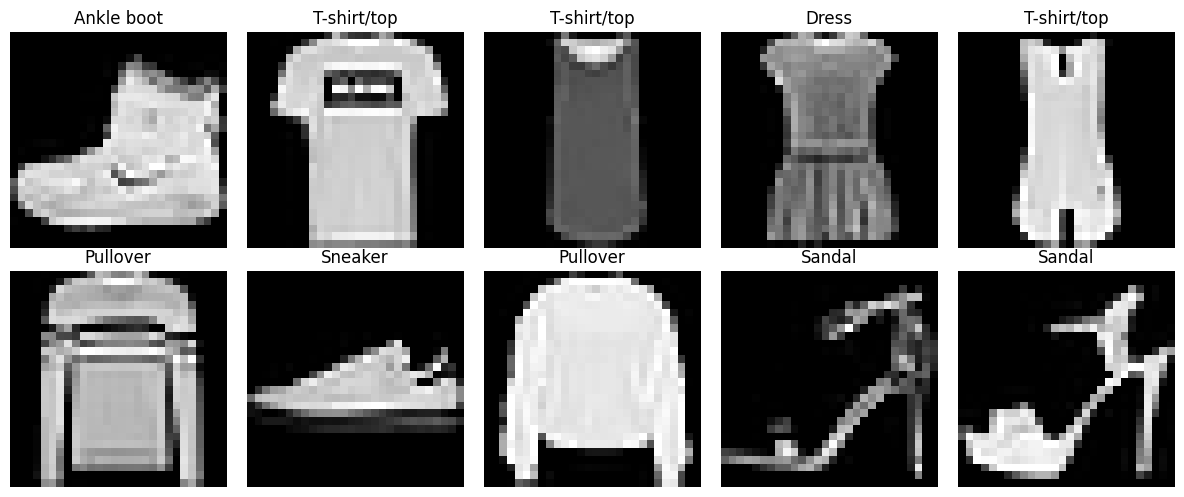

In [ ]:
class_names = [
    "T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
    "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"
]

plt.figure(figsize=(12, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i].squeeze(), cmap="gray")
    plt.title(class_names[y_train[i]])
    plt.axis("off")

plt.tight_layout()
plt.show()

## 6. Побудова CNN
Створіть модель `Sequential` для вхідних зображень розміру **28 × 28 × 1**. Відтворіть архітектуру з вихідного прикладу:

1. Згортковий блок: `Conv2D` з **32 фільтрами**, ядром **3 × 3**, активацією ReLU → `BatchNormalization` → `MaxPooling2D` (2 × 2) → `Dropout(0.25)`.
2. Другий аналогічний блок із **64 фільтрами**, `padding='same'`.
3. Третій аналогічний блок зі **128 фільтрами**, `padding='same'`.
4. `Flatten` → `Dense` на **512 нейронів** з ReLU → `BatchNormalization` → `Dropout(0.2)`.
5. Вихідний `Dense` на **10 нейронів** із `softmax`.

Присвойте модель змінній `model`. У комірці нижче самостійно запишіть її код.

In [ ]:
model = Sequential([
    Input(shape=(28, 28, 1)),

    Conv2D(32, (3, 3), activation="relu"),
    BatchNormalization(),
    MaxPooling2D(pool_size=(2, 2)),
    Dropout(0.25),

    Conv2D(64, (3, 3), activation="relu", padding="same"),
    BatchNormalization(),
    MaxPooling2D(pool_size=(2, 2)),
    Dropout(0.25),

    Conv2D(128, (3, 3), activation="relu", padding="same"),
    BatchNormalization(),
    MaxPooling2D(pool_size=(2, 2)),
    Dropout(0.25),

    Flatten(),
    Dense(512, activation="relu"),
    BatchNormalization(),
    Dropout(0.2),

    Dense(10, activation="softmax")
])

## 7. Компіляція моделі та перегляд архітектури
Скомпілюйте `model` з оптимізатором **Adam**, функцією втрат **categorical crossentropy** та метрикою **accuracy**.

Виведіть `model.summary()` і визначте загальну кількість параметрів моделі.

In [ ]:
model.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 26, 26, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 13, 13, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 13, 13, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 6, 6, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 6, 6, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 6, 6, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 6, 6, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 3, 3, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 3, 3, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1152)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │       590,336 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 512)            │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         5,130 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 691,082 (2.64 MB)

 Trainable params: 689,610 (2.63 MB)

 Non-trainable params: 1,472 (5.75 KB)

## 8. Налаштування навчання
Створіть два callback-об’єкти:

- `EarlyStopping`: моніторинг `val_loss`, `patience=10`, `restore_best_weights=True`.
- `ReduceLROnPlateau`: моніторинг `val_loss`, `factor=0.2`, `patience=3`, `min_lr=1e-6`.

Навчіть модель методом `fit()` із `batch_size=128`, `epochs=100`. Збережіть історію навчання у змінній `history`.

**Методична примітка:** у вихідному ноутбуці тестова вибірка використана як валідаційна. Для коректної незалежної фінальної оцінки рекомендовано виділити валідаційні дані **з навчальної вибірки** (наприклад, через `validation_split=0.1`) і залишити `x_test`, `y_test_cat` лише для розділу 9.

In [ ]:
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)

reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.2,
    patience=3,
    min_lr=1e-6
)

history = model.fit(
    x_train,
    y_train_cat,
    batch_size=128,
    epochs=100,
    validation_split=0.1,
    callbacks=[early_stopping, reduce_lr]
)

Epoch 1/100
422/422 ━━━━━━━━━━━━━━━━━━━━ 111s 254ms/step - accuracy: 0.8059 - loss: 0.5493 - val_accuracy: 0.6450 - val_loss: 1.2557 - learning_rate: 0.0010
Epoch 2/100
422/422 ━━━━━━━━━━━━━━━━━━━━ 108s 255ms/step - accuracy: 0.8671 - loss: 0.3589 - val_accuracy: 0.8880 - val_loss: 0.2982 - learning_rate: 0.0010
Epoch 3/100
422/422 ━━━━━━━━━━━━━━━━━━━━ 141s 252ms/step - accuracy: 0.8852 - loss: 0.3105 - val_accuracy: 0.9018 - val_loss: 0.2627 - learning_rate: 0.0010
Epoch 4/100
422/422 ━━━━━━━━━━━━━━━━━━━━ 106s 250ms/step - accuracy: 0.8954 - loss: 0.2828 - val_accuracy: 0.8767 - val_loss: 0.3174 - learning_rate: 0.0010
Epoch 5/100
422/422 ━━━━━━━━━━━━━━━━━━━━ 105s 249ms/step - accuracy: 0.8994 - loss: 0.2631 - val_accuracy: 0.9132 - val_loss: 0.2405 - learning_rate: 0.0010
Epoch 6/100
422/422 ━━━━━━━━━━━━━━━━━━━━ 106s 252ms/step - accuracy: 0.9075 - loss: 0.2475 - val_accuracy: 0.9175 - val_loss: 0.2188 - learning_rate: 0.0010
Epoch 7/100
422/422 ━━━━━━━━━━━━━━━━━━━━ 142s 253ms/step -

## 9. Оцінка на тестових даних і збереження моделі
Оцініть якість навченої моделі на `x_test` та `y_test_cat` за допомогою `model.evaluate()`. Виведіть `test_loss` і `test_acc`.

Збережіть модель у файл **`fashion_mnist_model.keras`**.

In [ ]:
test_loss, test_acc = model.evaluate(x_test, y_test_cat)

print("Test loss:", test_loss)
print("Test accuracy:", test_acc)

model.save("fashion_mnist_model.keras")

313/313 ━━━━━━━━━━━━━━━━━━━━ 6s 13ms/step - accuracy: 0.9309 - loss: 0.2031
Test loss: 0.20311130583286285
Test accuracy: 0.930899977684021


## 10. Графіки процесу навчання
За даними `history.history` побудуйте **два графіки поруч**:

- `accuracy` та `val_accuracy` за епохами;
- `loss` та `val_loss` за епохами.

Додайте заголовки, підписи осей, легенду та сітку. Опишіть, чи є ознаки перенавчання.

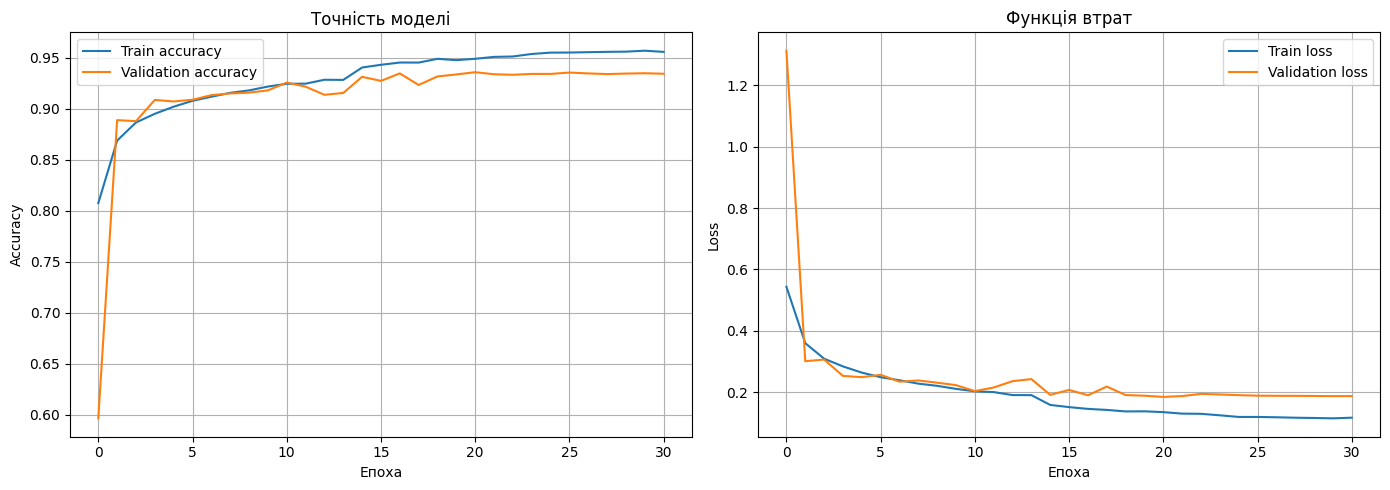

In [ ]:
plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Train accuracy")
plt.plot(history.history["val_accuracy"], label="Validation accuracy")
plt.title("Точність моделі")
plt.xlabel("Епоха")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Train loss")
plt.plot(history.history["val_loss"], label="Validation loss")
plt.title("Функція втрат")
plt.xlabel("Епоха")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

На початку навчання точність моделі зростала, а втрати зменшувалися. Приблизно після 12–15 епох показники на валідаційних даних майже не змінювалися, хоча на тренувальних продовжували покращуватися. Це свідчить про незначні ознаки перенавчання. Загалом модель навчилася добре та стабільно.

## 11. Прогнозування для випадкових зображень
Використайте `model.predict()` для отримання ймовірностей класів на тестовій вибірці. Знайдіть передбачені класи за допомогою `np.argmax()`.

Випадково оберіть **10 тестових зображень** без повторень і виведіть їх у сітці **2 × 5**. Для кожного вкажіть **істинний клас (True)** і **прогноз (Pred)**. Розгляньте приклади правильних та помилкових класифікацій.

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step


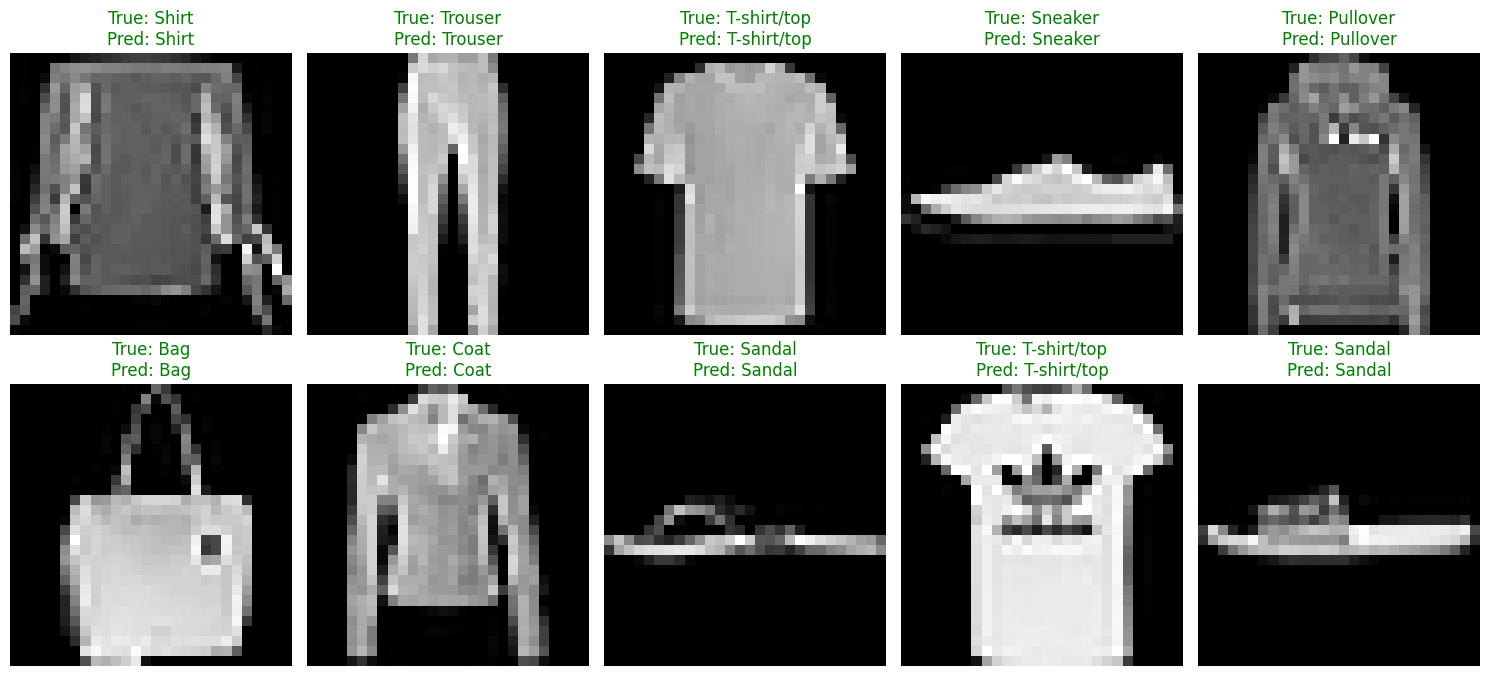

In [11]:
y_pred_prob = model.predict(x_test)
y_pred = np.argmax(y_pred_prob, axis=1)

random_indices = np.random.choice(len(x_test), 10, replace=False)

plt.figure(figsize=(15, 7))

for i, idx in enumerate(random_indices):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_test[idx].squeeze(), cmap="gray")
    plt.title(
        f"True: {class_names[y_test[idx]]}\nPred: {class_names[y_pred[idx]]}",
        color="green" if y_test[idx] == y_pred[idx] else "red"
    )
    plt.axis("off")

plt.tight_layout()
plt.show()

## 12. Висновки
Напишіть **власний** висновок (5–8 речень), спираючись на фактично отримані результати.

Дайте відповіді на запитання:

1. Якої точності досягнуто на тестовій вибірці?
2. Як змінювалися функція втрат і точність під час навчання? Чи є ознаки перенавчання?
3. Які класи модель плутає найчастіше серед переглянутих прикладів?
4. Для чого в архітектурі використовуються `BatchNormalization`, `MaxPooling2D` і `Dropout`?
5. Що можна змінити, аби покращити якість моделі?

**Ваш висновок:**

У ході роботи було створено та навчено CNN для класифікації зображень Fashion-MNIST. Точність моделі на тестовій вибірці становила 93,09%. Під час навчання точність зростала, а функція втрат зменшувалася, наприкінці з'явилися незначні ознаки перенавчання. Серед переглянутих прикладів модель найчастіше плутала схожі за виглядом предмети одягу. BatchNormalization стабілізує навчання, MaxPooling2D зменшує розмір зображень, а Dropout допомагає уникнути перенавчання. Для покращення результату можна змінити архітектуру мережі, підібрати інші параметри навчання або використати аугментацію зображень.